# Geometry fit: from impedance peaks to a didgeridoo

`didgelab.synth.fit_geometry` takes a few target resonances (frequency, impedance, Q) and finds a bore
whose simulated impedance spectrum has these resonances. This notebook explains

1. **Introduction**: what the geometry fit does and what it is good for
2. **Maths**: peak extraction, the bore model, the misfit and the optimisation
3. **Code examples**: fitting, checking a target, listening, and how accurate it is

## 1. Introduction

Normally DidgeLab works **from shape to sound**: you describe a bore (position and diameter along the
didgeridoo), DidgeLab simulates its *impedance spectrum*, and the peaks of that spectrum are the notes the
didgeridoo can play. The first peak is the drone, the higher ones are the toots. Each peak has three
properties:

* **frequency**: which note it is,
* **impedance**: how strong the resonance is (a high peak is easy to play and loud),
* **Q** (quality factor): how narrow the peak is. Q = frequency / width of the peak. A high Q means a narrow,
  focused resonance, a low Q a broad, soft one.

The geometry fit goes **the other way, from sound to shape**. You say *"I want a drone at D2, a toot at A3,
…"* and the fit searches for a bore that has these peaks. It works like a fast, simplified version of
the DidgeLab optimizer:

1. Start with a plausible bore: its length follows from the drone (a lower drone needs a longer didgeridoo),
   with a slightly flaring shape.
2. Simulate it, find its peaks and compare them with the target.
3. Change the length and the diameters a little in the direction that makes the peaks fit better.
4. Repeat until the peaks fit. First only the lowest three target peaks are used, then more, so that the
   search does not get lost.

After a few hundred simulations (a few seconds) you get a bore and a report of how well each peak was hit.

**What is it good for?**

* **Listening to a target.** The synthesizer (`didgelab.synth`) needs a bore, not only peaks: it also needs
  to know how the sound travels to the bell. With a fitted bore it plays a real, physically possible
  didgeridoo that has your peaks.
* **Checking a target.** Not every set of peaks can be built. If the fit cannot hit the target (e.g. two
  peaks only a few cents apart), the remaining error tells you so.
* **A starting point.** The fitted bore can be the starting shape for an optimization.

**What it is not.** Many different bores share the same first few peaks. The fit finds *one* of them, not
*the* didgeridoo you might have in mind. Everything the target does not specify (higher peaks, the
brightness of the sound) is whatever this bore happens to have. Fits of up to about 6–8 peaks are reliable;
for more peaks, use the optimizer.

## 2. Maths

### 2.1 Impedance spectrum

The input impedance $Z_{in}(f)$ of a bore is computed with the transmission-line model (TLM): the bore is a
chain of conical segments, each described by a transfer matrix, terminated by the radiation impedance of the
bell (see [transmission_line_model.md](../simulation_methods/acoustical_simulation/transmission_line_model.md)).
The fit uses the Cython implementation (`acoustical_simulation`), about 1 ms per spectrum.

### 2.2 Finding the peaks

$|Z_{in}|$ is simulated on a logarithmic grid $f_k = f_{min}\, e^{k h}$ with $h = 0.002$ (about 3.5 cents).
Let $y_k = \ln |Z_{in}(f_k)|$. At a local maximum $k$, a parabola through $y_{k-1}, y_k, y_{k+1}$ gives the
sub-grid offset

$$\delta = \frac{1}{2}\,\frac{y_{k-1} - y_{k+1}}{y_{k-1} - 2y_k + y_{k+1}}, \qquad
f_n = f_k\, e^{h\delta}, \qquad \ln Z_n = y_k - \frac{1}{4}(y_{k-1} - y_{k+1})\,\delta .$$

Near a resonance the impedance behaves like a second-order resonator,

$$|Z(f)| = \frac{Z_n}{\sqrt{1 + Q_n^2\left(\frac{f}{f_n} - \frac{f_n}{f}\right)^2}}
\quad\Rightarrow\quad
\ln|Z(f)| \approx \ln Z_n - 2 Q_n^2 \frac{(f - f_n)^2}{f_n^2},$$

so the curvature of the parabola gives the quality factor:

$$\frac{d^2 \ln|Z|}{df^2} = -\frac{4 Q_n^2}{f_n^2}
\quad\Rightarrow\quad
Q_n = f_n \sqrt{-\frac{1}{4}\frac{d^2 \ln|Z|}{df^2}}, \qquad
\frac{d^2 \ln|Z|}{df^2} \approx \frac{y_{k-1} - 2y_k + y_{k+1}}{(f_k h)^2}.$$

### 2.3 The bore model

The mouthpiece diameter $d_0$ is fixed. The free parameters are the length $L$ and $K$ diameters (default
$K = 12$) at equally spaced positions:

$$\theta = (L, \ln d_1, \dots, \ln d_K), \qquad x_j = \frac{j}{K} L, \quad j = 0 \dots K,$$

with straight (conical) segments in between, $0.6\,\text{m} \le L \le 3.5\,\text{m}$ and
$18\,\text{mm} \le d_j \le 140\,\text{mm}$. Diameters are optimised as logarithms so that a step means the
same relative change for a narrow and a wide part.

### 2.4 The misfit

For target peaks $(\hat f_n, \hat Z_n, \hat Q_n)$, $n = 1 \dots N$, and the peaks $(f_n, Z_n, Q_n)$ of the
bore (matched by order: the $n$-th peak of the bore to the $n$-th target), each target contributes three
residuals:

$$r_{n,f} = \frac{1200 \log_2(f_n / \hat f_n)}{10}, \qquad
r_{n,Z} = w_Z\, \frac{\ln(Z_n / \hat Z_n)}{\ln 1.25}, \qquad
r_{n,Q} = w_Q\, \frac{\ln(Q_n / \hat Q_n)}{\ln 1.25}.$$

At weight 1, an error of 10 cents counts as much as a factor of 1.25 in impedance or Q. The defaults
$w_Z = w_Q = 0.3$ make the frequencies the most important. If the bore has fewer than $N$ peaks below
$1.15\,\hat f_N$, the missing ones get a large penalty. The fit minimises

$$C(\theta) = \frac{1}{2} \sum_n \left(r_{n,f}^2 + r_{n,Z}^2 + r_{n,Q}^2\right).$$

### 2.5 Optimisation

$C$ is minimised with `scipy.optimize.least_squares` (trust-region reflective with bounds, Jacobian by
finite differences). Because the misfit is very bumpy (a peak can jump to another mode), the fit

* starts from four typical shapes: length $L = a\, c / \hat f_1$ with $a \in \{0.30, 0.36, 0.42\}$ (a
  closed-open cylinder has $a = 0.25$, a cone $a = 0.5$), and bells of 1.3–3 × the mouthpiece diameter;
* works in **stages**: first the lowest 3 target peaks, then 3 more, and so on. Each stage starts from the
  two best bores of the previous stage.

The result is the best bore of the last stage. `GeometryFit.cents`, `.impedance_ratio` and `.q_ratio`
report how well each target was hit.

## 3. Code examples

In [1]:
import sys, time
sys.path.insert(0, "../../src")   # use the didgelab of this repository

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

from didgelab import acoustical_simulation, Geo, compute_moist_air_properties
from didgelab.synth import Bore, fit_geometry, render_song_loop_from_peaks

constants = compute_moist_air_properties(temp_celsius=28)

def plot_fit(fit, original=None, fmax=1200):
    # bore (left) and impedance spectrum with the target peaks (right)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.5))
    f = np.arange(30, fmax, 1.0)
    for geo, label, style in [(original, "original", "--"), (fit.geometry, "fitted", "-")]:
        if geo is None:
            continue
        g = np.array(geo)
        a1.plot(g[:, 0], g[:, 1] / 2, style, label=label)
        a1.plot(g[:, 0], -g[:, 1] / 2, style, color=a1.lines[-1].get_color())
        z = np.asarray(acoustical_simulation(Geo(geo), f, constants=constants)).ravel()
        a2.plot(f, z / 1e6, style, label=label)
    a2.plot([t.freq for t in fit.targets], [t.impedance / 1e6 for t in fit.targets], "o", color="k", label="target")
    a1.set(xlabel="position (mm)", ylabel="radius (mm)", title="bore"); a1.legend()
    a2.set(xlabel="frequency (Hz)", ylabel="|Z| (MPa s/m³)", yscale="log", title="impedance spectrum"); a2.legend()
    plt.show()

def report(fit):
    print(f"{'target Hz':>10} {'fitted Hz':>10} {'cents':>7} {'Z ratio':>8} {'Q ratio':>8}")
    for t, p, c, zr, qr in zip(fit.targets, fit.peaks, fit.cents, fit.impedance_ratio, fit.q_ratio):
        print(f"{t.freq:10.1f} {p.freq if p else float('nan'):10.1f} {c:7.1f} {zr:8.2f} {qr:8.2f}")
    print(f"max error {fit.max_cents:.1f} cents, {fit.nfev} simulations")

### 3.1 Fitting the peaks of a known bore

A good test: take an existing bore, compute its peaks, and fit a bore to the first six of them. The fitted
bore hits the peaks closely, but it is a different shape: many bores share the same first peaks.

fit took 1.2 s
 target Hz  fitted Hz   cents  Z ratio  Q ratio
      75.2       75.2    -0.0     1.08     1.44
     194.3      194.4     0.5     0.97     1.22
     306.6      306.6     0.2     1.00     0.99
     422.8      422.9     0.3     1.04     1.06
     538.1      538.1     0.1     0.99     1.10
     656.3      656.0    -0.8     1.00     1.28
max error 0.8 cents, 1534 simulations


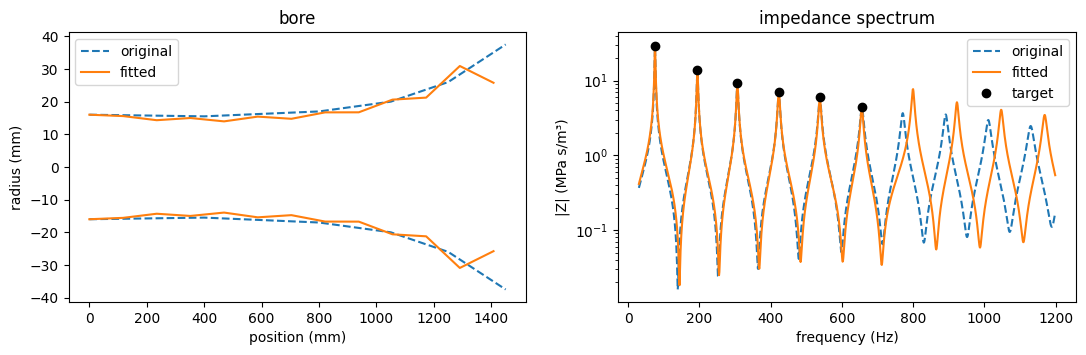

In [2]:
original = [[0, 32], [400, 31], [800, 34], [1050, 40], [1250, 52], [1450, 75]]
peaks = Bore(original, constants=constants).resonances[:6]   # Resonance(freq, impedance, q)

t = time.time()
fit = fit_geometry(peaks, mouth_diameter=32, constants=constants)
print(f"fit took {time.time() - t:.1f} s")
report(fit)
plot_fit(fit, original)

### 3.2 A target from scratch

In practice the target comes from the user: a drone at D2 and three toots. Impedance is given in
Pa·s/m³ (the unit of DidgeLab); typical values are 10–25 MPa·s/m³ for the drone and a few MPa·s/m³ for
the toots. Q is typically 15–40. Q has a low weight in the misfit, so it is only matched roughly.

 target Hz  fitted Hz   cents  Z ratio  Q ratio
      73.4       73.4     0.5     1.44     1.74
     196.0      196.1     0.7     1.98     2.26
     311.1      311.0    -0.5     2.56     2.61
     440.0      439.8    -0.7     3.05     3.02
max error 0.7 cents, 1416 simulations


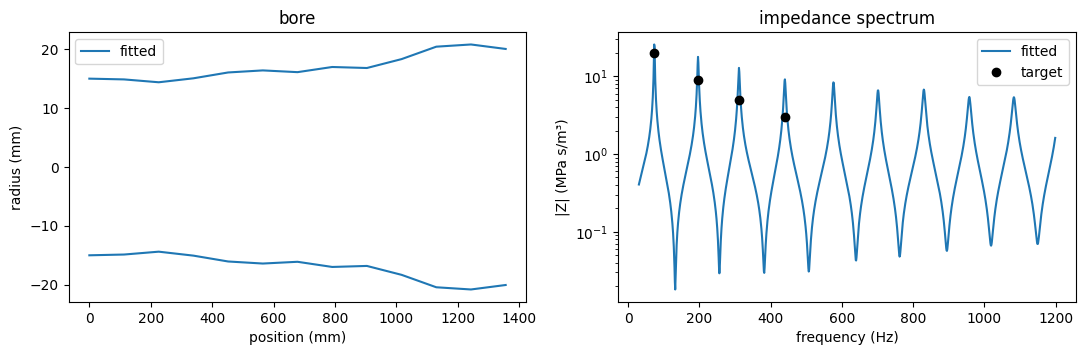

fitted bore: [[0, 30.0], [113, 29.7], [226, 28.8], [339, 30.1], [452, 32.1], [565, 32.8], [678, 32.2], [791, 34.0], [904, 33.6], [1017, 36.6], [1130, 40.9], [1243, 41.6], [1356, 40.1]]


In [3]:
target = [
    (73.4, 2.0e7, 25),    # D2, drone
    (196.0, 9.0e6, 30),   # G3
    (311.1, 5.0e6, 30),   # D#4
    (440.0, 3.0e6, 30),   # A4
]
fit = fit_geometry(target, mouth_diameter=30, constants=constants)
report(fit)
plot_fit(fit)
print("fitted bore:", [[round(x), round(d, 1)] for x, d in fit.geometry])

### 3.3 Checking a target

Two resonances only 30 cents apart cannot both be peaks of a didgeridoo: they would merge into one. The fit
finds a bore with the first peak, but it has no second peak there: the second target is reported as missing
(`nan`) and `fit.max_cents` is infinite. `fit.max_cents` is a simple sanity check, e.g. *"more than 10 cents
off: this target is probably not buildable"*.

In [4]:
fit = fit_geometry([(70.0, 2e7, 20), (71.2, 2e7, 20)], constants=constants)
report(fit)

 target Hz  fitted Hz   cents  Z ratio  Q ratio
      70.0       70.0    -0.8     1.32     2.23
      71.2        nan     nan      nan      nan
max error inf cents, 261 simulations


### 3.4 Listening

`render_song_loop_from_peaks` renders a song for a bore given only by its peaks. With
`method="modal"` the bore is a `ModalBore` (a sum of resonators: instant, pitches exact, the transfer to the
bell is approximated). With `method="geometry"` a bore is fitted first and the real bore is played.

In [5]:
for method in ("modal", "geometry"):
    t = time.time()
    y, fs = render_song_loop_from_peaks(target, "tiki-du", mouth_diameter=30, method=method)
    print(f"{method}: {time.time() - t:.1f} s")
    display(Audio(y, rate=fs))

modal: 5.2 s


geometry: 7.7 s


### 3.5 How accurate is the sound?

The fit reproduces the target peaks, but how close is the *sound* to the original didgeridoo? This was
measured on the eight bores of the [Didge Archive](https://github.com/didgitaldoo/didge-archive): for each
bore, a sustained drone was rendered from the original geometry, from a `ModalBore` with all its peaks below
3 kHz, and from a bore fitted to its first six peaks. The table gives the brightness (spectral centroid)
relative to the original geometry (1.00 = equally bright).

| bore | ModalBore (all peaks) | geometry fit (6 peaks) |
|---|---|---|
| arusha | 1.50 | 1.10 |
| kizimkazi | 0.89 | 0.96 |
| malveira | 0.92 | 1.27 |
| matema | 1.12 | 1.26 |
| nazare | 1.12 | 1.23 |
| opendidgeridoo | 0.59 | 0.87 |
| tamaki1 | 0.54 | 0.54 |
| tamaki2 | 0.56 | 1.00 |
| **mean deviation** | **38 %** | **22 %** |

The pitches are right in both cases. The geometry fit is right on average (geometric mean 1.00), the
`ModalBore` somewhat dark (0.85), and a single didgeridoo can sound noticeably brighter or darker than the
original. The first peaks do not determine the timbre: it depends on the higher peaks and on the shape
between them. (Drone renders with the mouth of a "doo" and the default parameters of the synthesizer.)

**Standard shapes.** Fitting standard shapes (cone, cylinder + bell, cone + bell, each with small
corrections) instead of the free bore was tried as well. It did not help: the archive bores are irregular
optimised shapes, so standard shapes miss their peaks by more (some by 35–250 cents) and were on average
too bright (mean deviation 33 %; measured with the earlier radiation impedance of DidgeLab ≤ 3.0.x).

### 3.6 The bell in the transmission-line model

The bell matters for the sound, and the TLM sees it: at the bell end the TLM uses a radiation impedance
(end correction and radiated sound power). A wide bell radiates more sound at higher frequencies, so less
is reflected back into the bore: the higher peaks become lower and broader (for a 100 mm bell the Q of the
peaks above 500 Hz drops from about 100 to 55), and all peaks move up a little. Below, the same 1.5 m bore as a cylinder and with a 60 mm and a 100 mm bell.

cylinder       60 Hz Q 40   173 Hz Q 65   288 Hz Q 80   404 Hz Q 93   520 Hz Q 101   635 Hz Q 105
60 mm bell     64 Hz Q 42   183 Hz Q 69   301 Hz Q 83   415 Hz Q 85   526 Hz Q 88   638 Hz Q 86
100 mm bell    67 Hz Q 43   191 Hz Q 69   314 Hz Q 81   429 Hz Q 73   533 Hz Q 58   637 Hz Q 55


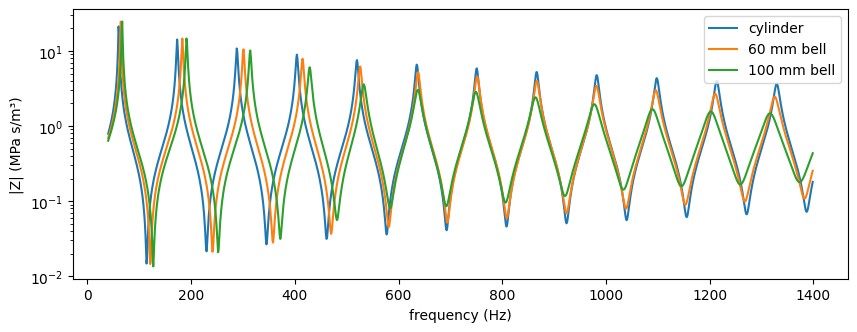

In [6]:
from didgelab.synth.geofit import find_peaks

def with_bell(bell_d, L=1500, bell_len=300, d0=32, dc=36):
    x = np.linspace(0, L - bell_len, 10)
    geo = [[float(a), float(d0 + (dc - d0) * a / (L - bell_len))] for a in x]
    xb = np.linspace(L - bell_len, L, 12)[1:]
    return geo + [[float(a), float(dc + (bell_d - dc) * ((a - L + bell_len) / bell_len) ** 2)] for a in xb]

f = np.arange(40, 1400, 1.0)
fig, ax = plt.subplots(figsize=(10, 3.5))
for bell_d, label in [(36, "cylinder"), (60, "60 mm bell"), (100, "100 mm bell")]:
    geo = with_bell(bell_d)
    z = np.asarray(acoustical_simulation(Geo(geo), f, constants=constants)).ravel()
    ax.plot(f, z / 1e6, label=label)
    print(f"{label:12s}", "  ".join(f"{p.freq:4.0f} Hz Q {p.q:2.0f}" for p in find_peaks(geo, 900, constants)[:6]))
ax.set(xlabel="frequency (Hz)", ylabel="|Z| (MPa s/m³)", yscale="log")
ax.legend(); plt.show()

**Limits.** The TLM treats the sound in each segment as plane waves and the bell end as a simple radiating
opening. In a strongly flaring bell the wavefronts are curved, so for large bells the higher peaks are less
accurate. DidgeLab's 2D/3D FEM backends cannot serve as a reference here: they set the pressure to zero at
the bell end and do not model radiation (see
[2d_fem.md](../simulation_methods/acoustical_simulation/2d_fem.md)).